# Практикум: аналіз і прогнозування часових рядів

Цей notebook доповнює лекцію **«Аналіз і прогнозування часових рядів. Навчання та оцінка моделі»**.

Мета практикуму — послідовно пройти основні етапи прогнозування:

1. підготовка часових даних;
2. візуальний аналіз;
3. дослідження тренду та сезонності;
4. коректний часовий поділ на train/test;
5. побудова базових прогнозів;
6. оцінювання якості за MAE, RMSE, sMAPE та MASE;
7. застосування ETS;
8. застосування SARIMA;
9. використання Prophet;
10. побудова ML-моделі на лагових і календарних ознаках;
11. покрокова ретроспективна перевірка;
12. самостійні завдання.

**Важливо:** у часових рядах не можна випадково перемішувати спостереження перед поділом на навчальну і тестову вибірки.

## 1. Підключення бібліотек

In [ ]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.ensemble import HistGradientBoostingRegressor

from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.statespace.sarimax import SARIMAX

pd.set_option("display.max_columns", 50)
np.random.seed(42)

## 2. Формування навчального часового ряду

Щоб notebook можна було виконувати без завантаження зовнішніх файлів, використаємо штучно сформований щоденний ряд продажів. Він містить:

- довгостроковий тренд;
- тижневу сезонність;
- річну сезонність;
- підвищення попиту у вихідні;
- випадковий шум;
- декілька аномальних значень.

Такий ряд зручний для демонстрації основних етапів forecasting.

In [ ]:
dates = pd.date_range("2022-01-01", "2025-12-31", freq="D")
n = len(dates)
t = np.arange(n)

trend = 100 + 0.035 * t
weekly = 12 * np.sin(2 * np.pi * t / 7)
yearly = 8 * np.sin(2 * np.pi * t / 365.25)
weekend = np.where(dates.dayofweek >= 5, 10, 0)
noise = np.random.normal(0, 6, n)

sales = trend + weekly + yearly + weekend + noise

df = pd.DataFrame({
    "date": dates,
    "sales": sales
})

# Додаємо кілька пропусків та аномалій для демонстрації підготовки даних
missing_idx = [120, 450, 900]
outlier_idx = [300, 700, 1100]

df.loc[missing_idx, "sales"] = np.nan
df.loc[outlier_idx, "sales"] *= 1.7

df.head()

,date,sales
0,2022-01-01,112.980285
1,2022-01-02,118.725005
2,2022-01-03,115.930451
3,2022-01-04,114.862459
4,2022-01-05,94.078518


In [ ]:
print(df.shape)
print(df.dtypes)
print("\nКількість пропусків:")
print(df.isna().sum())

(1461, 2)
date     datetime64[ns]
sales           float64
dtype: object

Кількість пропусків:
date     0
sales    3
dtype: int64


### Завдання 1. Первинний аналіз

1. Виведіть останні 10 рядків.
2. Визначте мінімальну та максимальну дату.
3. Обчисліть середнє, медіану, стандартне відхилення, мінімум і максимум `sales`.
4. Перевірте, чи є дублікати дат.

In [ ]:
# Ваш код тут
display(df.tail(10))
print(f"Діапазон дат: {df['date'].min().date()} — {df['date'].max().date()}")
print(df['sales'].agg(['mean', 'median', 'std', 'min', 'max']))
print("Дублікатів дат:", df['date'].duplicated().sum())

,date,sales
1451,2025-12-22,171.328008
1452,2025-12-23,156.237492
1453,2025-12-24,160.161011
1454,2025-12-25,141.622914
1455,2025-12-26,130.154195
1456,2025-12-27,164.792801
1457,2025-12-28,172.113885
1458,2025-12-29,170.054977
1459,2025-12-30,160.035508
1460,2025-12-31,144.925047


Діапазон дат: 2022-01-01 — 2025-12-31
mean      128.868405
median    128.307405
std        19.969577
min        78.054031
max       279.572480
Name: sales, dtype: float64
Дублікатів дат: 0


## 3. Підготовка часових даних

Для подальшого аналізу необхідно:

- перетворити дату у формат `datetime`;
- відсортувати дані;
- зробити дату індексом;
- перевірити регулярність часового кроку;
- обробити пропущені значення.

У цьому прикладі пропуски заповнюються часовою інтерполяцією.

In [ ]:
df["date"] = pd.to_datetime(df["date"])
df = df.sort_values("date").drop_duplicates(subset="date")
df = df.set_index("date")

print(pd.infer_freq(df.index))

df["sales"] = df["sales"].interpolate(method="time")

print("Пропусків після інтерполяції:", df["sales"].isna().sum())
df.head()

D
Пропусків після інтерполяції: 0


,sales
date,
2022-01-01,112.980285
2022-01-02,118.725005
2022-01-03,115.930451
2022-01-04,114.862459
2022-01-05,94.078518


### Завдання 2. Робота з пропусками

Створіть копію набору даних `df_task` і штучно видаліть значення `sales` для п'яти довільних дат.

Порівняйте три способи заповнення:

- `ffill`;
- лінійну інтерполяцію;
- часову інтерполяцію.

Коротко поясніть, який спосіб доцільніший для цього ряду.

In [ ]:
# Ваш код тут
df_task = df.copy()
df_task.loc[df_task.sample(5, random_state=42).index, "sales"] = np.nan

res = pd.DataFrame({
    "ffill": df_task["sales"].ffill(),
    "linear": df_task["sales"].interpolate(method="linear"),
    "time": df_task["sales"].interpolate(method="time")
})
display(res.loc[df_task["sales"].isna()])

,ffill,linear,time
date,,,
2023-02-18,101.595618,121.705620,121.705620
2023-06-07,130.269937,121.809579,121.809579
2024-06-11,148.899627,142.339196,142.339196
2024-11-02,129.367357,134.740349,134.740349
2025-01-10,134.721514,144.255729,144.255729


## 4. Візуальний аналіз

Графік часового ряду є першим інструментом діагностики. За ним оцінюють:

- загальний напрям зміни;
- сезонні коливання;
- можливі структурні зміни;
- викиди;
- зміну дисперсії.

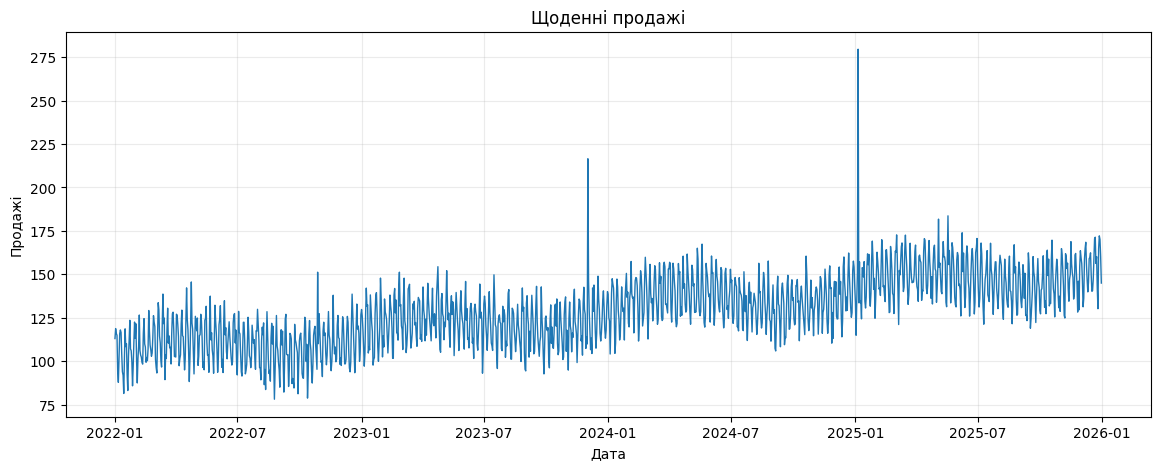

In [ ]:
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(df.index, df["sales"], linewidth=1)
ax.set_title("Щоденні продажі")
ax.set_xlabel("Дата")
ax.set_ylabel("Продажі")
ax.grid(alpha=0.25)
plt.show()

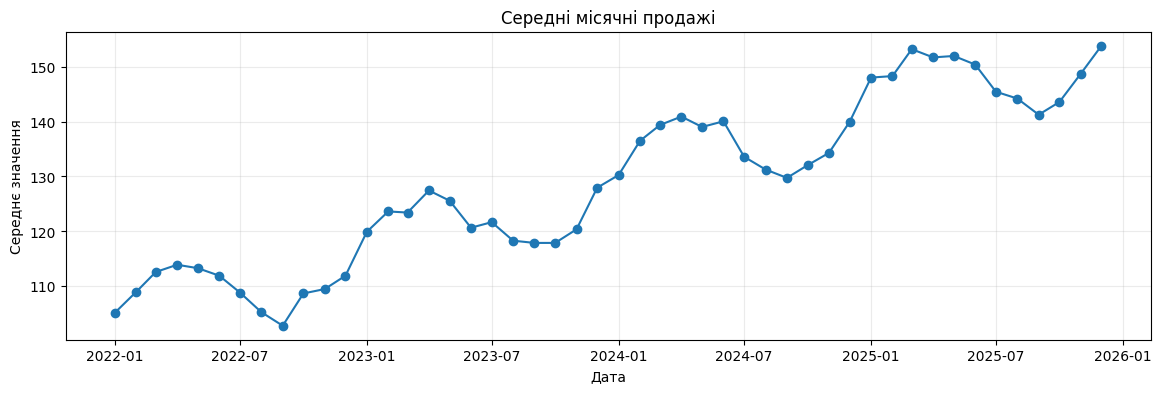

In [ ]:
monthly = df["sales"].resample("MS").mean()

fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(monthly.index, monthly.values, marker="o")
ax.set_title("Середні місячні продажі")
ax.set_xlabel("Дата")
ax.set_ylabel("Середнє значення")
ax.grid(alpha=0.25)
plt.show()

### Завдання 3. Візуалізація

1. Побудуйте графік останніх 90 днів.
2. Побудуйте 7-денне та 30-денне ковзні середні.
3. Поясніть, чим відрізняється інформація на цих двох графіках.

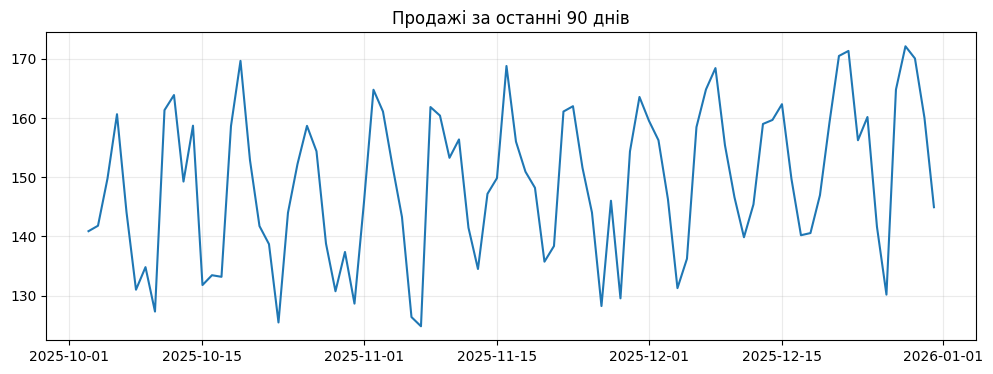

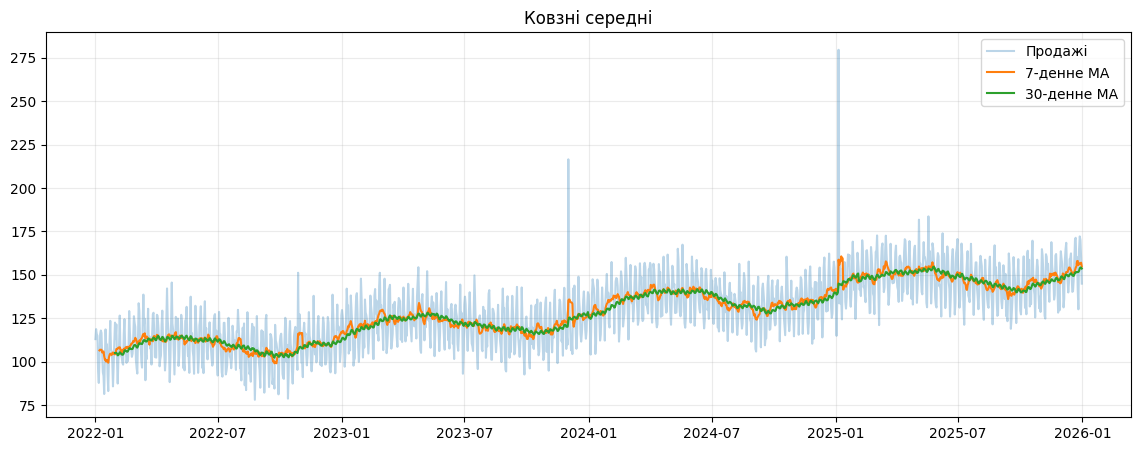

In [ ]:
# Ваш код тут

# 1. Графік останніх 90 днів
last_90 = df.tail(90)

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(last_90.index, last_90["sales"], label="Продажі")
ax.set_title("Продажі за останні 90 днів")
ax.grid(alpha=0.25)
plt.show()

# 2. 7-денне та 30-денне ковзні середні
df["ma_7"] = df["sales"].rolling(7).mean()
df["ma_30"] = df["sales"].rolling(30).mean()

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(df.index, df["sales"], alpha=0.3, label="Продажі")
ax.plot(df.index, df["ma_7"], label="7-денне MA")
ax.plot(df.index, df["ma_30"], label="30-денне MA")
ax.set_title("Ковзні середні")
ax.legend()
ax.grid(alpha=0.25)
plt.show()

## 5. Декомпозиція ряду методом STL

STL-декомпозиція розкладає часовий ряд на:

- **trend** — довгострокову тенденцію;
- **seasonal** — сезонну складову;
- **resid** — залишкову складову.

Для щоденних даних з тижневою сезонністю використаємо `period=7`.

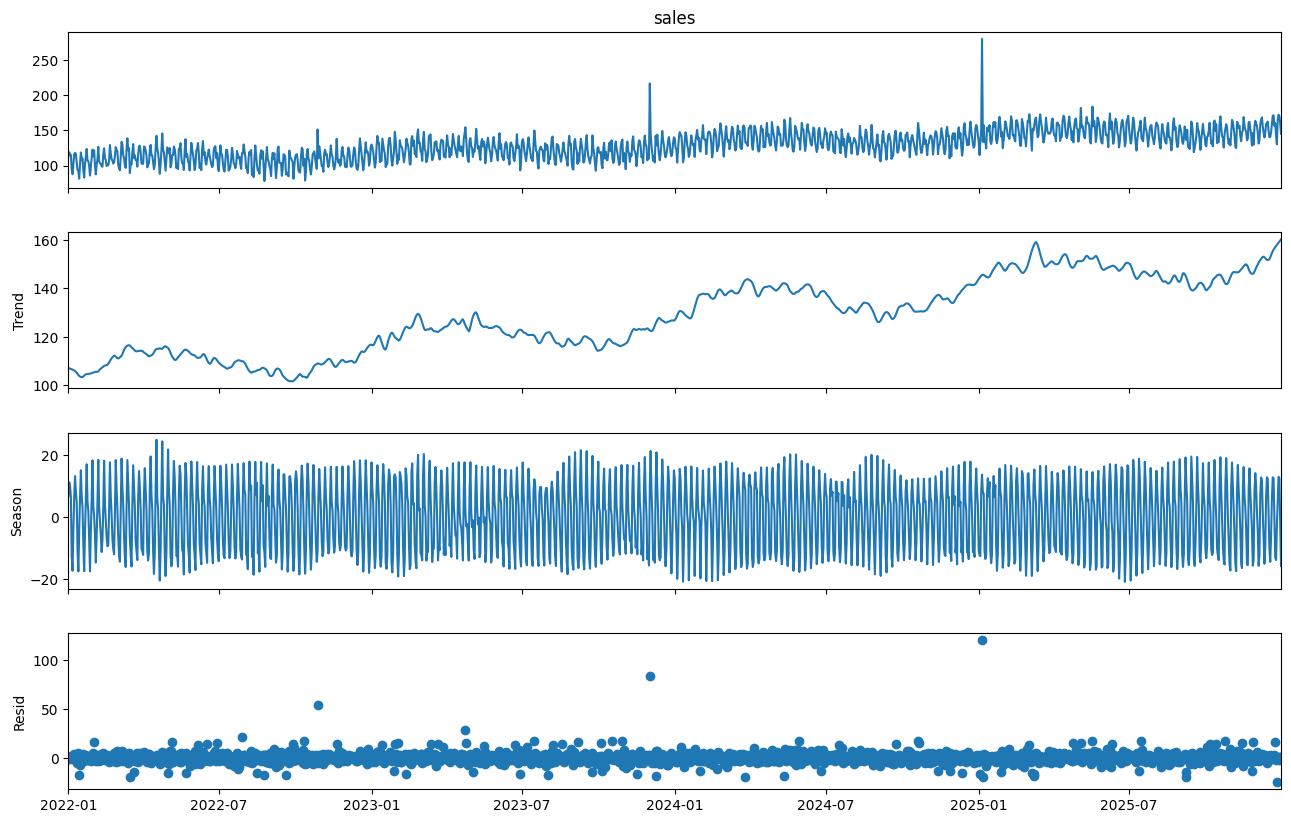

In [ ]:
stl = STL(df["sales"], period=7, robust=True)
stl_result = stl.fit()

fig = stl_result.plot()
fig.set_size_inches(14, 9)
plt.show()

### Завдання 4. Декомпозиція

1. Повторіть STL-декомпозицію для місячного ряду.
2. Оберіть обґрунтований період сезонності.
3. Проаналізуйте тренд та залишки.

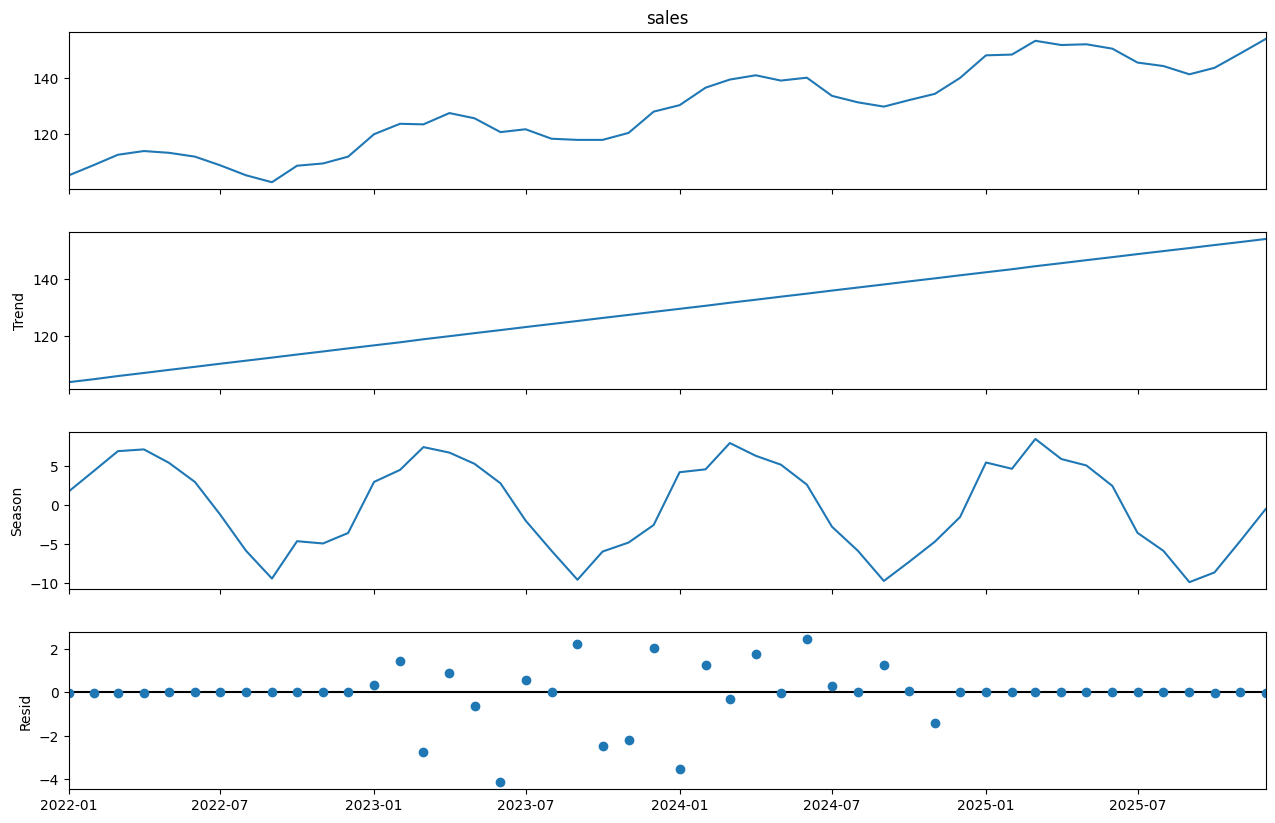

In [ ]:
# Ваш код тут

monthly_sales = df["sales"].resample("MS").mean().dropna()

stl_monthly = STL(monthly_sales, period=12, robust=True)
stl_m_result = stl_monthly.fit()

fig = stl_m_result.plot()
fig.set_size_inches(14, 9)
plt.show()

## 6. Часовий поділ train/test

У звичайних задачах машинного навчання дані часто перемішують. Для часових рядів це зазвичай неприпустимо.

Нехай останні 90 днів становлять тестовий період. Усі попередні спостереження використовуються для навчання.

In [ ]:
horizon = 90

train = df.iloc[:-horizon].copy()
test = df.iloc[-horizon:].copy()

print("Train:", train.index.min().date(), "—", train.index.max().date(), len(train))
print("Test :", test.index.min().date(), "—", test.index.max().date(), len(test))

Train: 2022-01-01 — 2025-10-02 1371
Test : 2025-10-03 — 2025-12-31 90


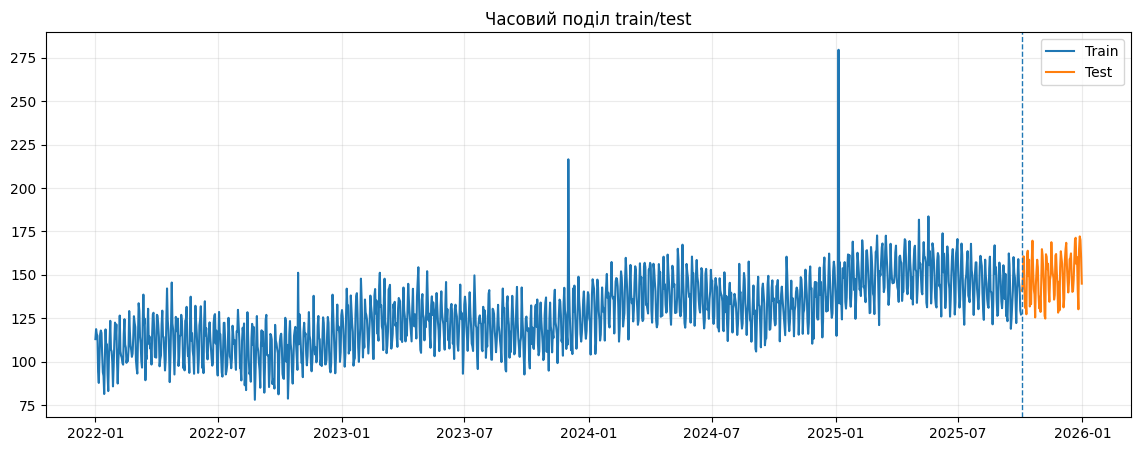

In [ ]:
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(train.index, train["sales"], label="Train")
ax.plot(test.index, test["sales"], label="Test")
ax.axvline(test.index.min(), linestyle="--", linewidth=1)
ax.legend()
ax.set_title("Часовий поділ train/test")
ax.grid(alpha=0.25)
plt.show()

### Завдання 5. Часовий поділ

Створіть інший варіант поділу, у якому тестовий період дорівнює 60 дням.

Виведіть:

- кількість спостережень у train;
- кількість спостережень у test;
- останню дату train;
- першу дату test.

In [ ]:
# Ваш код тут
horizon_task = 60
train_task = df.iloc[:-horizon_task].copy()
test_task = df.iloc[-horizon_task:].copy()

print("Спостережень у train:", len(train_task))
print("Спостережень у test:", len(test_task))
print("Остання дата train:", train_task.index.max().date())
print("Перша дата test:", test_task.index.min().date())

Спостережень у train: 1401
Спостережень у test: 60
Остання дата train: 2025-11-01
Перша дата test: 2025-11-02


## 7. Базові моделі прогнозування

Перед використанням складної моделі потрібно побудувати простий базовий прогноз.

### Naive forecast
Прогноз дорівнює останньому відомому значенню.

### Seasonal naive
Прогноз повторює значення попереднього сезонного циклу. Для щоденних даних з тижневою сезонністю використаємо лаг 7.

In [ ]:
naive_pred = np.repeat(train["sales"].iloc[-1], len(test))

history = pd.concat([train["sales"], test["sales"]])
seasonal_naive_pred = history.shift(7).loc[test.index].values

baseline = pd.DataFrame({
    "actual": test["sales"].values,
    "naive": naive_pred,
    "seasonal_naive": seasonal_naive_pred
}, index=test.index)

baseline.head()

,actual,naive,seasonal_naive
date,,,
2025-10-03,140.875312,127.213304,137.575710
2025-10-04,141.794922,127.213304,148.849817
2025-10-05,149.768594,127.213304,159.044241
2025-10-06,160.638161,127.213304,145.953075
2025-10-07,144.109047,127.213304,142.430282


## 8. Метрики якості прогнозу

Використаємо:

- **MAE** — середню абсолютну помилку;
- **RMSE** — квадратний корінь із середньоквадратичної помилки;
- **sMAPE** — симетричну відносну помилку;
- **MASE** — масштабовану абсолютну помилку.

Менше значення метрики зазвичай означає кращий прогноз.

In [ ]:
def rmse(y_true, y_pred):
    return np.sqrt(mean_squared_error(y_true, y_pred))

def smape(y_true, y_pred):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    denom = (np.abs(y_true) + np.abs(y_pred))
    mask = denom != 0
    return 100 * np.mean(
        2 * np.abs(y_pred[mask] - y_true[mask]) / denom[mask]
    )

def mase(y_true, y_pred, y_train, seasonality=1):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    y_train = np.asarray(y_train)

    scale = np.mean(
        np.abs(y_train[seasonality:] - y_train[:-seasonality])
    )
    return np.mean(np.abs(y_true - y_pred)) / scale

def evaluate(y_true, y_pred, y_train, seasonality=7):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": rmse(y_true, y_pred),
        "sMAPE_%": smape(y_true, y_pred),
        "MASE": mase(y_true, y_pred, y_train, seasonality)
    }

results = pd.DataFrame({
    "Naive": evaluate(test["sales"], naive_pred, train["sales"], 7),
    "Seasonal naive": evaluate(test["sales"], seasonal_naive_pred, train["sales"], 7)
}).T

results

,MAE,RMSE,sMAPE_%,MASE
Naive,22.039691,25.297086,15.570350,3.108885
Seasonal naive,7.734062,9.380056,5.276847,1.090955


### Завдання 6. Метрики

1. Визначте, яка базова модель є кращою.
2. Поясніть, чому висновок не слід робити лише за однією метрикою.
3. Обчисліть MAE окремо для перших і останніх 30 днів тестового періоду.

In [ ]:
# Ваш код тут
print(results)

mae_first_30 = mean_absolute_error(test["sales"].iloc[:30], seasonal_naive_pred[:30])
mae_last_30 = mean_absolute_error(test["sales"].iloc[-30:], seasonal_naive_pred[-30:])

print("MAE (перші 30 днів):", mae_first_30)
print("MAE (останні 30 днів):", mae_last_30)

                      MAE       RMSE    sMAPE_%      MASE
Naive           22.039691  25.297086  15.570350  3.108885
Seasonal naive   7.734062   9.380056   5.276847  1.090955
MAE (перші 30 днів): 8.15544519336499
MAE (останні 30 днів): 6.76778499215381


## 9. Експоненційне згладжування ETS

Моделі ETS описують часовий ряд через рівень, тренд і сезонність.

Для навчального прикладу використаємо:

- адитивний тренд;
- адитивну сезонність;
- сезонний період 7 днів.

In [ ]:
ets_model = ExponentialSmoothing(
    train["sales"],
    trend="add",
    seasonal="add",
    seasonal_periods=7,
    initialization_method="estimated"
).fit()

ets_pred = ets_model.forecast(len(test))

ets_metrics = evaluate(
    test["sales"],
    ets_pred,
    train["sales"],
    seasonality=7
)

ets_metrics

{'MAE': 13.11452610803631,
 'RMSE': np.float64(15.229020700077848),
 'sMAPE_%': np.float64(9.14961742586639),
 'MASE': np.float64(1.8499146745742305)}

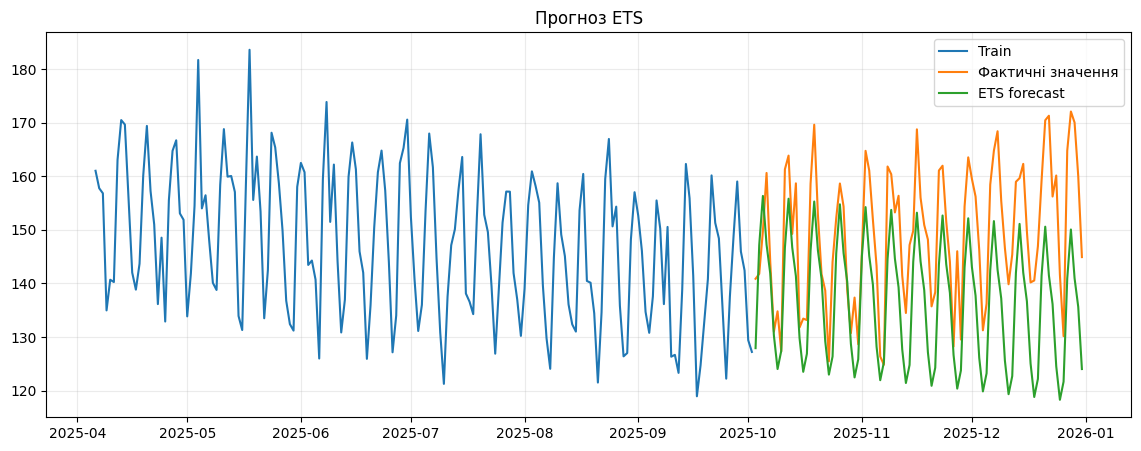

In [ ]:
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(train.index[-180:], train["sales"].iloc[-180:], label="Train")
ax.plot(test.index, test["sales"], label="Фактичні значення")
ax.plot(test.index, ets_pred, label="ETS forecast")
ax.legend()
ax.set_title("Прогноз ETS")
ax.grid(alpha=0.25)
plt.show()

### Завдання 7. ETS

1. Побудуйте ETS-модель без тренду.
2. Порівняйте її з поточною моделлю.
3. Додайте результати обох ETS-моделей до таблиці метрик.

In [ ]:
# Ваш код тут
ets_no_trend = ExponentialSmoothing(
    train["sales"],
    trend=None,
    seasonal="add",
    seasonal_periods=7,
    initialization_method="estimated"
).fit()

ets_no_trend_pred = ets_no_trend.forecast(len(test))

results.loc["ETS (add, add)"] = evaluate(test["sales"], ets_pred, train["sales"], 7)
results.loc["ETS (none, add)"] = evaluate(test["sales"], ets_no_trend_pred, train["sales"], 7)

display(results)

,MAE,RMSE,sMAPE_%,MASE
Naive,22.039691,25.297086,15.570350,3.108885
Seasonal naive,7.734062,9.380056,5.276847,1.090955
"ETS (add, add)",13.114526,15.229021,9.149617,1.849915
"ETS (none, add)",8.894899,10.703167,6.091459,1.254701


## 10. SARIMA

SARIMA розширює ARIMA сезонними компонентами.

У загальному випадку модель записують як:

**SARIMA(p, d, q)(P, D, Q, s)**,

де `s` — довжина сезонного циклу.

Нижче використано невелику модель, щоб приклад виконувався відносно швидко.

In [ ]:
sarima_model = SARIMAX(
    train["sales"],
    order=(1, 1, 1),
    seasonal_order=(1, 0, 1, 7),
    enforce_stationarity=False,
    enforce_invertibility=False
).fit(disp=False)

sarima_forecast = sarima_model.get_forecast(steps=len(test))
sarima_pred = sarima_forecast.predicted_mean
sarima_ci = sarima_forecast.conf_int()

sarima_metrics = evaluate(
    test["sales"],
    sarima_pred,
    train["sales"],
    seasonality=7
)

sarima_metrics

{'MAE': 7.7465658208202095,
 'RMSE': np.float64(9.401756189500011),
 'sMAPE_%': np.float64(5.302245527656123),
 'MASE': np.float64(1.0927185375542505)}

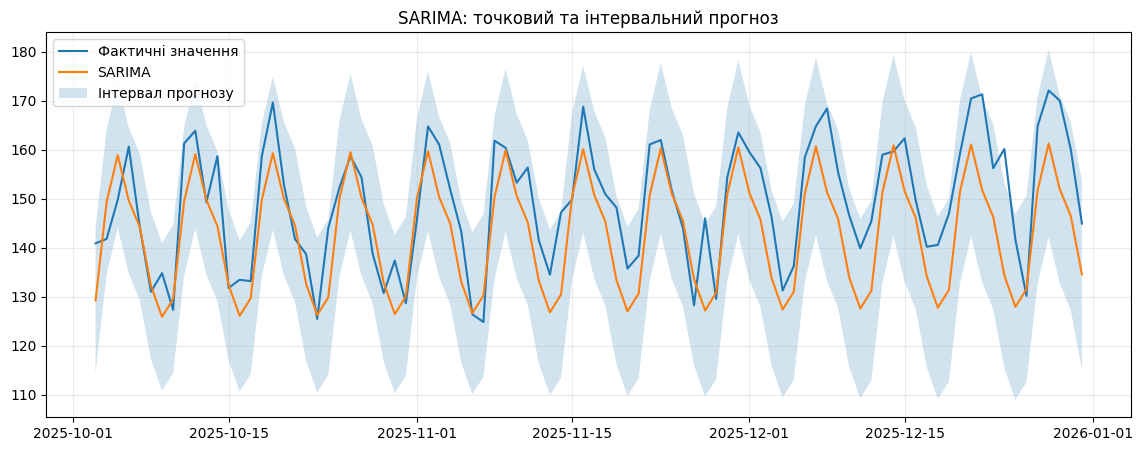

In [ ]:
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(test.index, test["sales"], label="Фактичні значення")
ax.plot(test.index, sarima_pred, label="SARIMA")
ax.fill_between(
    test.index,
    sarima_ci.iloc[:, 0].values,
    sarima_ci.iloc[:, 1].values,
    alpha=0.2,
    label="Інтервал прогнозу"
)
ax.legend()
ax.set_title("SARIMA: точковий та інтервальний прогноз")
ax.grid(alpha=0.25)
plt.show()

### Завдання 8. SARIMA

Змініть параметри моделі, наприклад:

- `order=(2, 1, 1)`;
- `seasonal_order=(1, 1, 0, 7)`.

Порівняйте MAE та RMSE з попередньою SARIMA-моделлю.

**Примітка:** мета завдання — зрозуміти вплив параметрів, а не виконати повний автоматичний підбір.

In [ ]:
# Ваш код тут
sarima_new = SARIMAX(
    train["sales"],
    order=(2, 1, 1),
    seasonal_order=(1, 1, 0, 7),
    enforce_stationarity=False,
    enforce_invertibility=False
).fit(disp=False)

sarima_new_pred = sarima_new.get_forecast(steps=len(test)).predicted_mean

results.loc["SARIMA (old)"] = sarima_metrics
results.loc["SARIMA (new)"] = evaluate(test["sales"], sarima_new_pred, train["sales"], 7)

display(results.loc[["SARIMA (old)", "SARIMA (new)"]])

,MAE,RMSE,sMAPE_%,MASE
SARIMA (old),7.746566,9.401756,5.302246,1.092719
SARIMA (new),8.092037,9.663575,5.528950,1.141450


## 11. Prophet

Prophet зручно використовувати для рядів з трендом, сезонністю та календарними ефектами.

У Prophet назви основних стовпців мають бути:

- `ds` — дата;
- `y` — цільове значення.

Якщо бібліотека не встановлена, у Google Colab її можна встановити командою:

```python
!pip -q install prophet
```

In [ ]:
!pip -q install prophet


In [ ]:
from prophet import Prophet

prophet_train = (
    train.reset_index()
         .rename(columns={"date": "ds", "sales": "y"})
)

model_prophet = Prophet(
    weekly_seasonality=True,
    yearly_seasonality=True,
    daily_seasonality=False,
    seasonality_mode="additive"
)

model_prophet.fit(prophet_train)

future = model_prophet.make_future_dataframe(
    periods=len(test),
    freq="D"
)

forecast = model_prophet.predict(future)

prophet_pred = (
    forecast.set_index("ds")
            .loc[test.index, "yhat"]
)

results.loc["Prophet"] = evaluate(
    test["sales"],
    prophet_pred,
    train["sales"],
    seasonality=7
)

display(results.loc[["Prophet"]])

,MAE,RMSE,sMAPE_%,MASE
Prophet,5.301959,6.437513,3.619983,0.747886


### Завдання 9. Prophet

Після встановлення `prophet`:

1. навчіть модель;
2. отримайте прогноз на тестовий період;
3. побудуйте графік;
4. виведіть компоненти моделі;
5. порівняйте MAE з ETS та SARIMA.

,MAE
"ETS (add, add)",13.114526
SARIMA (old),7.746566
Prophet,5.301959


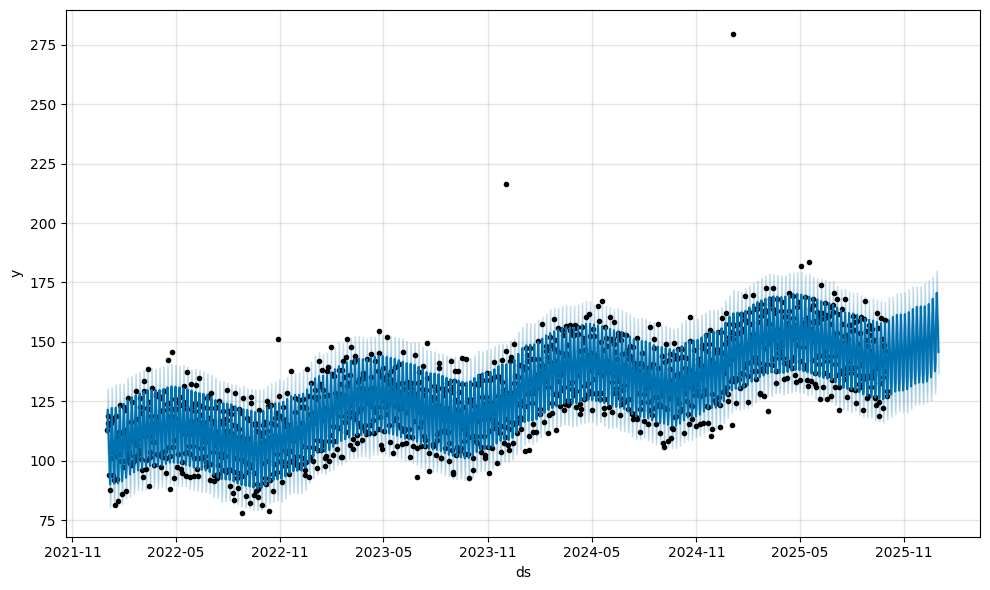

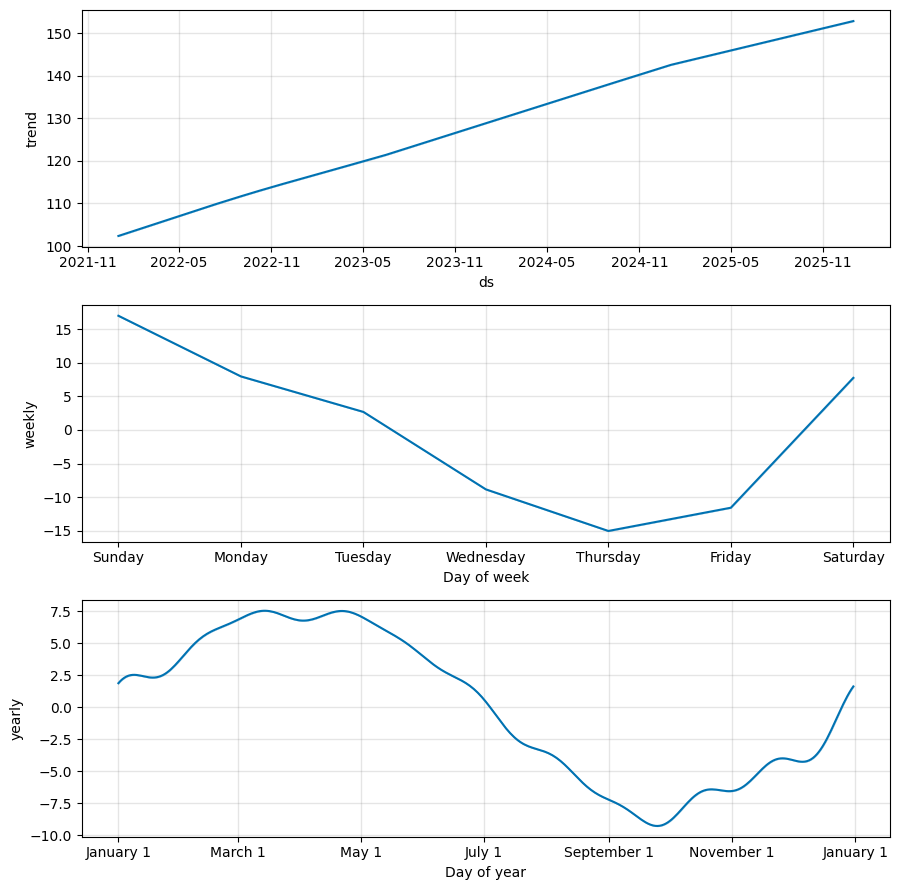

In [ ]:
# Ваш код тут

fig1 = model_prophet.plot(forecast)
fig2 = model_prophet.plot_components(forecast)

metrics_cmp = results.loc[["ETS (add, add)", "SARIMA (old)", "Prophet"], ["MAE"]]
display(metrics_cmp)

## 12. Ознаки для машинного навчання

Для використання класичних ML-моделей часовий ряд перетворюють на табличний набір ознак.

Типові ознаки:

- лаги;
- ковзні середні;
- день тижня;
- місяць;
- день року;
- ознака вихідного дня.

**Критичний момент:** ковзні характеристики мають обчислюватися тільки за минулими значеннями. Саме тому перед `rolling()` використовується `shift(1)`.

In [ ]:
def make_features(series):
    data = pd.DataFrame({"y": series.copy()})

    for lag in [1, 2, 3, 7, 14, 28]:
        data[f"lag_{lag}"] = data["y"].shift(lag)

    data["roll_mean_7"] = data["y"].shift(1).rolling(7).mean()
    data["roll_mean_28"] = data["y"].shift(1).rolling(28).mean()
    data["roll_std_7"] = data["y"].shift(1).rolling(7).std()

    data["dayofweek"] = data.index.dayofweek
    data["month"] = data.index.month
    data["dayofyear"] = data.index.dayofyear
    data["is_weekend"] = (data.index.dayofweek >= 5).astype(int)

    return data

ml_df = make_features(df["sales"]).dropna()
ml_df.head()

,y,lag_1,lag_2,lag_3,lag_7,lag_14,lag_28,roll_mean_7,roll_mean_28,roll_std_7,dayofweek,month,dayofyear,is_weekend
date,,,,,,,,,,,,,,
2022-01-29,111.082231,97.400770,85.764899,99.669338,112.207900,102.048594,112.980285,104.512145,104.134824,11.932523,5,1,29,1
2022-01-30,122.474286,111.082231,97.400770,85.764899,123.513016,118.574712,118.725005,104.351335,104.067036,11.818566,6,1,30,1
2022-01-31,113.086640,122.474286,111.082231,97.400770,107.038953,108.356362,115.930451,104.202945,104.200939,11.541145,0,1,31,0
2022-02-01,121.472125,113.086640,122.474286,111.082231,105.990140,109.993414,114.862459,105.066901,104.099374,12.005835,1,2,32,0
2022-02-02,100.017166,121.472125,113.086640,122.474286,99.669338,92.413005,94.078518,107.278613,104.335434,13.533155,2,2,33,0


In [ ]:
ml_train = ml_df.loc[ml_df.index < test.index.min()].copy()
ml_test = ml_df.loc[ml_df.index >= test.index.min()].copy()

X_train = ml_train.drop(columns="y")
y_train = ml_train["y"]

X_test = ml_test.drop(columns="y")
y_test = ml_test["y"]

gbr = HistGradientBoostingRegressor(
    learning_rate=0.05,
    max_iter=300,
    max_leaf_nodes=15,
    l2_regularization=1.0,
    random_state=42
)

gbr.fit(X_train, y_train)
ml_pred = gbr.predict(X_test)

ml_metrics = evaluate(
    y_test,
    ml_pred,
    train["sales"],
    seasonality=7
)

ml_metrics

{'MAE': 6.4256724041518165,
 'RMSE': np.float64(7.708139982015866),
 'sMAPE_%': np.float64(4.411484230090363),
 'MASE': np.float64(0.9063953646912981)}

### Зауваження щодо попереднього прикладу

Цей приклад демонструє **табличне формування ознак** та оцінювання моделі. Для реального багатокрокового прогнозу потрібно чітко визначити, які ознаки будуть відомі у момент прогнозування.

Якщо для майбутніх дат лагова ознака використовує фактичне значення, яке на момент прогнозу ще невідоме, виникає **витік даних**.

Для багатокрокового прогнозування застосовують, зокрема:

- recursive strategy;
- direct strategy;
- multi-output strategy.

### Завдання 10. Feature engineering

Додайте щонайменше три нові ознаки:

- лаг 21;
- 14-денне ковзне середнє;
- номер тижня року.

Перенавчіть модель та порівняйте результат.

Після цього перевірте, чи всі створені ознаки могли бути відомими на момент формування прогнозу.

In [ ]:
# Ваш код тут

def make_features_new(series):
    data = pd.DataFrame({"y": series.copy()})

    for lag in [1, 2, 3, 7, 14, 21, 28]:
        data[f"lag_{lag}"] = data["y"].shift(lag)

    data["roll_mean_7"] = data["y"].shift(1).rolling(7).mean()
    data["roll_mean_14"] = data["y"].shift(1).rolling(14).mean()
    data["roll_mean_28"] = data["y"].shift(1).rolling(28).mean()
    data["roll_std_7"] = data["y"].shift(1).rolling(7).std()

    data["dayofweek"] = data.index.dayofweek
    data["month"] = data.index.month
    data["dayofyear"] = data.index.dayofyear
    data["weekofyear"] = data.index.isocalendar().week.astype(int)
    data["is_weekend"] = (data.index.dayofweek >= 5).astype(int)

    return data

ml_df_new = make_features_new(df["sales"]).dropna()

ml_train_new = ml_df_new.loc[ml_df_new.index < test.index.min()].copy()
ml_test_new = ml_df_new.loc[ml_df_new.index >= test.index.min()].copy()

X_train_new = ml_train_new.drop(columns="y")
y_train_new = ml_train_new["y"]
X_test_new = ml_test_new.drop(columns="y")
y_test_new = ml_test_new["y"]

gbr.fit(X_train_new, y_train_new)
ml_pred_new = gbr.predict(X_test_new)

results.loc["ML (new features)"] = evaluate(
    y_test, ml_pred_new, train["sales"], seasonality=7
)

display(results.loc[["ML (new features)"]])

,MAE,RMSE,sMAPE_%,MASE
ML (new features),5.990184,7.541486,4.104727,0.844966


## 13. Порівняння моделей

Зведемо результати моделей у єдину таблицю.

In [ ]:
comparison = pd.DataFrame({
    "Naive": evaluate(test["sales"], naive_pred, train["sales"], 7),
    "Seasonal naive": evaluate(test["sales"], seasonal_naive_pred, train["sales"], 7),
    "ETS": ets_metrics,
    "SARIMA": sarima_metrics,
    "ML": ml_metrics
}).T

comparison.sort_values("MAE")

,MAE,RMSE,sMAPE_%,MASE
ML,6.425672,7.708140,4.411484,0.906395
Seasonal naive,7.734062,9.380056,5.276847,1.090955
SARIMA,7.746566,9.401756,5.302246,1.092719
ETS,13.114526,15.229021,9.149617,1.849915
Naive,22.039691,25.297086,15.570350,3.108885


### Завдання 11. Порівняння

Дайте письмову відповідь у Markdown-комірці:

1. Яка модель показала найменший MAE?
2. Чи перевершує вона seasonal naive?
3. Чи однаковий висновок за MAE, RMSE, sMAPE та MASE?
4. Яку модель Ви обрали б для практичного використання і чому?

**Ваша відповідь:**

Найменший MAE показала ML модель (приблизно 6.43).   

Так, вона помітно перевершує Seasonal naive (у якої MAE становить близько 7.73).

Так, висновок однаковий: за всіма метриками (MAE, RMSE, sMAPE та MASE) найкращі результати демонструє ML, за нею йдуть Seasonal naive, SARIMA, ETS і на останньому місці найпростіша Naive.   

Для практичного використання варто обрати ML-модель, оскільки вона забезпечує найвищу точність прогнозу завдяки використанню лагових та календарних ознак, які ефективно виловлюють як тренди, так і складніші закономірності в даних.

## 14. Покрокова ретроспективна перевірка

Один train/test split може дати випадковий результат. Надійніший підхід — кілька разів імітувати ситуацію, коли модель навчається тільки на минулому та прогнозує наступний часовий відрізок.

Нижче реалізовано спрощений rolling-origin backtesting для seasonal naive.

In [ ]:
def rolling_seasonal_naive_cv(series, initial=700, horizon=28, step=28, seasonality=7):
    rows = []

    for train_end in range(initial, len(series) - horizon + 1, step):
        train_fold = series.iloc[:train_end]
        test_fold = series.iloc[train_end:train_end + horizon]

        full = pd.concat([train_fold, test_fold])
        pred = full.shift(seasonality).loc[test_fold.index]

        rows.append({
            "train_end": train_fold.index.max(),
            "test_start": test_fold.index.min(),
            "test_end": test_fold.index.max(),
            "MAE": mean_absolute_error(test_fold, pred),
            "RMSE": rmse(test_fold, pred)
        })

    return pd.DataFrame(rows)

cv_results = rolling_seasonal_naive_cv(
    df["sales"],
    initial=700,
    horizon=28,
    step=28,
    seasonality=7
)

cv_results

,train_end,test_start,test_end,MAE,RMSE
0,2023-12-01,2023-12-02,2023-12-29,11.726037,22.703319
1,2023-12-29,2023-12-30,2024-01-26,6.347953,7.977381
2,2024-01-26,2024-01-27,2024-02-23,6.816896,7.867398
3,2024-02-23,2024-02-24,2024-03-22,5.245028,6.584598
4,2024-03-22,2024-03-23,2024-04-19,7.455005,9.252134
5,2024-04-19,2024-04-20,2024-05-17,6.096014,7.548739
6,2024-05-17,2024-05-18,2024-06-14,7.319789,9.073672
7,2024-06-14,2024-06-15,2024-07-12,6.137219,7.365825
8,2024-07-12,2024-07-13,2024-08-09,5.629306,6.705414
9,2024-08-09,2024-08-10,2024-09-06,6.042439,7.485644


In [ ]:
cv_results[["MAE", "RMSE"]].agg(["mean", "std", "min", "max"])

,MAE,RMSE
mean,7.299416,9.797419
std,1.943769,5.694299
min,5.245028,6.584598
max,14.629295,34.184076


### Завдання 12. Backtesting

1. Змініть `horizon` з 28 на 14 днів.
2. Порівняйте середню MAE.
3. Побудуйте графік MAE для всіх fold.
4. Поясніть, що показує варіативність похибки між fold.

,MAE,RMSE
mean,7.299416,9.641162
std,2.414533,5.908296
min,4.472537,6.010704
max,17.867067,34.317041


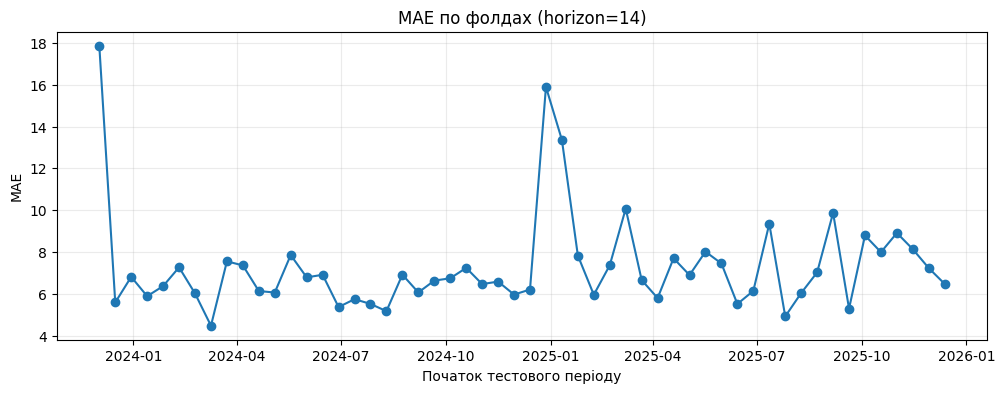

In [ ]:
# Ваш код тут
cv_results_14 = rolling_seasonal_naive_cv(
    df["sales"],
    initial=700,
    horizon=14,
    step=14,
    seasonality=7
)

display(cv_results_14[["MAE", "RMSE"]].agg(["mean", "std", "min", "max"]))

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(cv_results_14["test_start"], cv_results_14["MAE"], marker="o")
ax.set_title("MAE по фолдах (horizon=14)")
ax.set_xlabel("Початок тестового періоду")
ax.set_ylabel("MAE")
ax.grid(alpha=0.25)
plt.show()

## 15. Додаткове завдання: прогнозні інтервали

Точковий прогноз показує одне найбільш очікуване значення. На практиці важливо також оцінювати невизначеність.

Використайте інтервал прогнозу SARIMA і визначте, яка частка фактичних значень тестової вибірки потрапила між нижньою та верхньою межами.

In [ ]:
# Ваш код тут
lower_bound = sarima_ci.iloc[:, 0]
upper_bound = sarima_ci.iloc[:, 1]
actuals = test["sales"]

in_interval = (actuals >= lower_bound) & (actuals <= upper_bound)
fraction = in_interval.mean()

print(f"Частка фактичних значень у межах прогнозного інтервалу: {fraction:.2%}")

Частка фактичних значень у межах прогнозного інтервалу: 96.67%


## 16. Підсумкове практичне завдання

Виконайте повний цикл прогнозування самостійно.

### Умова

Використайте часовий ряд `df["sales"]`.

### Необхідно

1. Провести первинний аналіз.
2. Перевірити пропуски та регулярність часової шкали.
3. Побудувати графік ряду.
4. Виконати STL-декомпозицію.
5. Виділити останні 60 днів як test.
6. Побудувати seasonal naive.
7. Побудувати одну статистичну модель: ETS або SARIMA.
8. Побудувати одну ML-модель.
9. Обчислити MAE, RMSE, sMAPE і MASE.
10. Порівняти моделі.
11. Побудувати графік найкращого прогнозу.
12. Сформулювати короткий висновок.

### Висновок має містити

- яка модель є найкращою;
- наскільки вона перевершує baseline;
- які закономірності виявлено в ряді;
- які обмеження має отриманий прогноз.

In [ ]:
if "date" in df.columns:
    df["date"] = pd.to_datetime(df["date"])
    df = df.sort_values("date").drop_duplicates(subset="date")
    df = df.set_index("date")
else:
    df.index = pd.to_datetime(df.index)
    df = df.sort_index()

df["sales"] = df["sales"].interpolate(method="time")
print("Пропусків після інтерполяції:", df["sales"].isna().sum())

# 1. Первинний аналіз
display(df.tail())
print(f"Діапазон дат: {df.index.min().date()} — {df.index.max().date()}")
print(df['sales'].agg(['mean', 'median', 'std', 'min', 'max']))
print("Дублікатів дат:", df.index.duplicated().sum())

Пропусків після інтерполяції: 0


,sales,ma_7,ma_30
date,,,
2025-12-27,164.792801,156.396657,152.274727
2025-12-28,172.113885,156.630043,153.694291
2025-12-29,170.054977,156.448182,154.217755
2025-12-30,160.035508,156.990756,154.100560
2025-12-31,144.925047,154.814189,153.613838


Діапазон дат: 2022-01-01 — 2025-12-31
mean      128.866427
median    128.296899
std        19.950851
min        78.054031
max       279.572480
Name: sales, dtype: float64
Дублікатів дат: 0


In [ ]:
# 2. Підготовка даних
# Ваш код тут
if "date" in df.columns:
    df["date"] = pd.to_datetime(df["date"])
    df = df.sort_values("date").drop_duplicates(subset="date")
    df = df.set_index("date")
else:
    df.index = pd.to_datetime(df.index)
    df = df.sort_index()

df["sales"] = df["sales"].interpolate(method="time")
print("Пропусків після інтерполяції:", df["sales"].isna().sum())

Пропусків після інтерполяції: 0


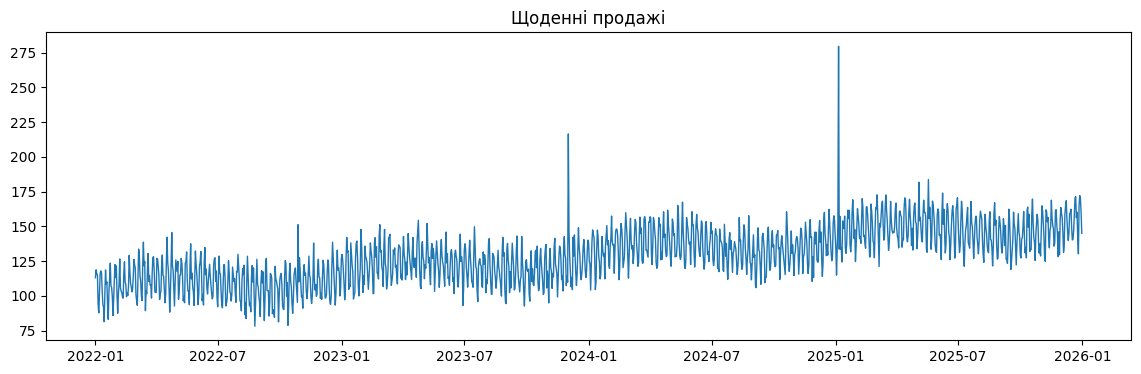

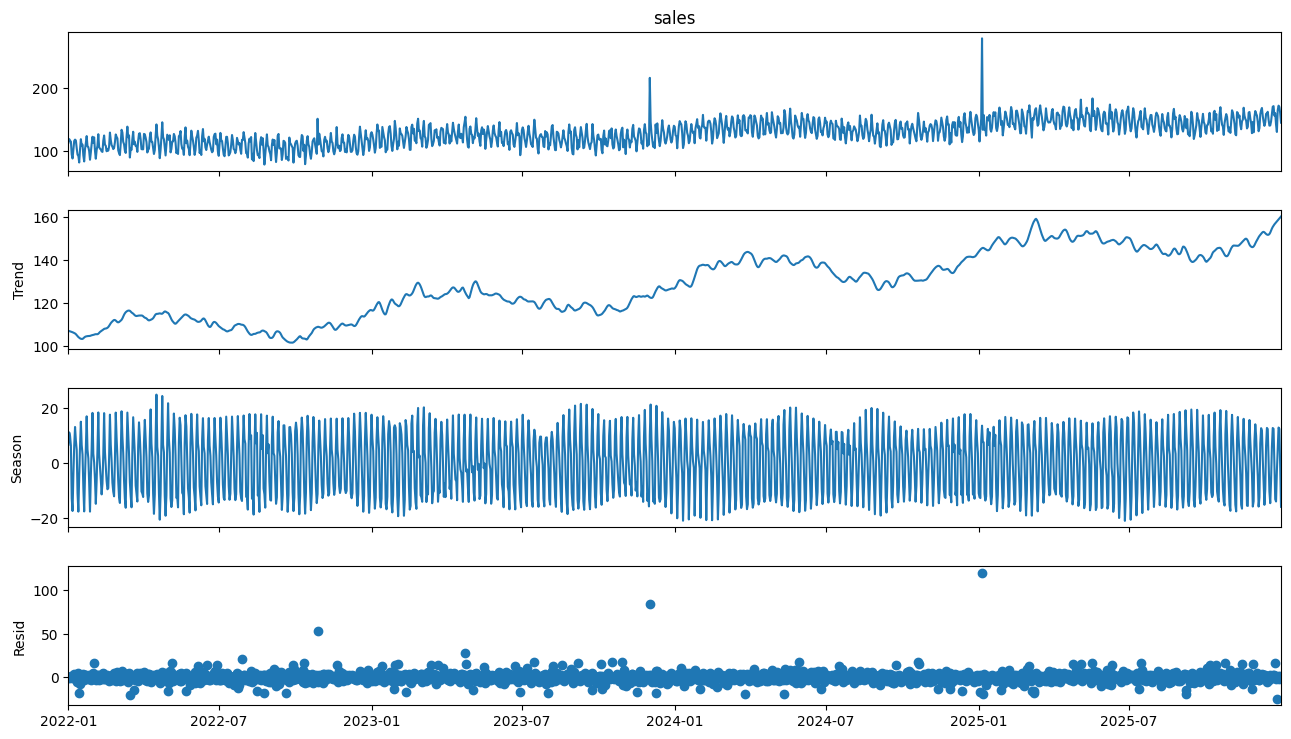

In [ ]:
# 3. Візуалізація та STL
# Ваш код тут
fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(df.index, df["sales"], linewidth=1)
ax.set_title("Щоденні продажі")
plt.show()

stl = STL(df["sales"], period=7, robust=True)
fig = stl.fit().plot()
fig.set_size_inches(14, 8)
plt.show()

In [ ]:
# 4. Train/test split
# Ваш код тут
horizon = 60
train = df.iloc[:-horizon].copy()
test = df.iloc[-horizon:].copy()
print("Train:", len(train), "| Test:", len(test))

Train: 1401 | Test: 60


In [ ]:
# 5. Seasonal naive baseline
# Ваш код тут
history = pd.concat([train["sales"], test["sales"]])
seasonal_naive_pred = history.shift(7).loc[test.index].values

In [ ]:
# 6. Статистична модель
# Ваш код тут
ets_model = ExponentialSmoothing(
    train["sales"], trend="add", seasonal="add", seasonal_periods=7, initialization_method="estimated"
).fit()
ets_pred = ets_model.forecast(len(test))

In [ ]:
# 7. ML-модель
# Ваш код тут
def make_features(series):
    data = pd.DataFrame({"y": series.copy()})
    for lag in [1, 2, 3, 7, 14, 28]:
        data[f"lag_{lag}"] = data["y"].shift(lag)
    data["roll_mean_7"] = data["y"].shift(1).rolling(7).mean()
    data["dayofweek"] = data.index.dayofweek
    data["month"] = data.index.month
    data["is_weekend"] = (data.index.dayofweek >= 5).astype(int)
    return data

ml_df = make_features(df["sales"]).dropna()
ml_train = ml_df.loc[ml_df.index < test.index.min()].copy()
ml_test = ml_df.loc[ml_df.index >= test.index.min()].copy()

gbr = HistGradientBoostingRegressor(random_state=42)
gbr.fit(ml_train.drop(columns="y"), ml_train["y"])
ml_pred = gbr.predict(ml_test.drop(columns="y"))

In [ ]:
# 8. Порівняння метрик
# Ваш код тут
final_results = pd.DataFrame({
    "Seasonal naive": evaluate(test["sales"], seasonal_naive_pred, train["sales"], 7),
    "ETS": evaluate(test["sales"], ets_pred, train["sales"], 7),
    "ML": evaluate(test["sales"], ml_pred, train["sales"], 7)
}).T
display(final_results)

,MAE,RMSE,sMAPE_%,MASE
Seasonal naive,7.523370,9.241039,5.107073,1.057811
ETS,6.417538,7.731201,4.339170,0.902327
ML,6.006614,7.067238,4.047095,0.844550


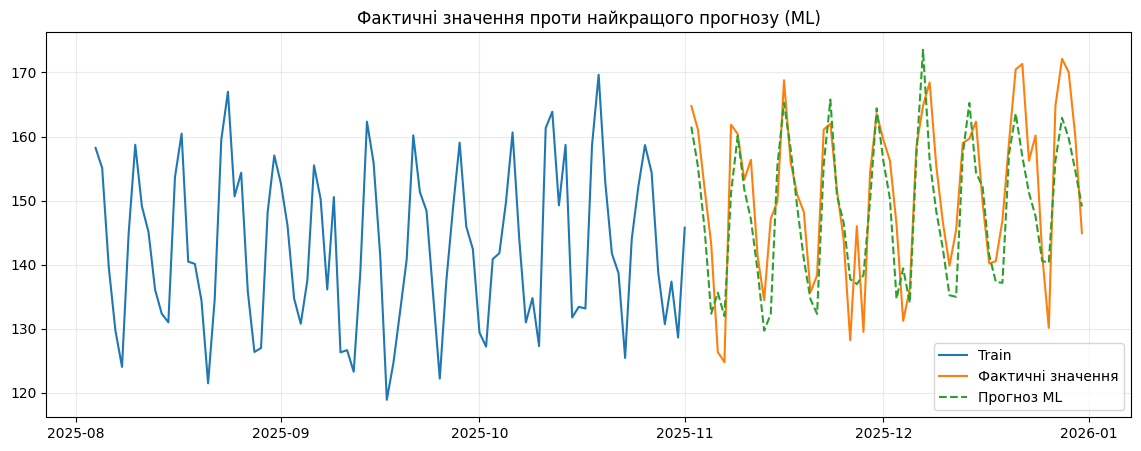

In [ ]:
# 9. Фінальний графік
# Ваш код тут
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(train.index[-90:], train["sales"].iloc[-90:], label="Train")
ax.plot(test.index, test["sales"], label="Фактичні значення")
ax.plot(test.index, ml_pred, label="Прогноз ML", linestyle="--")
ax.legend()
ax.set_title("Фактичні значення проти найкращого прогнозу (ML)")
ax.grid(alpha=0.25)
plt.show()

### Підсумковий висновок

Напишіть 5–8 речень академічним стилем.

**Ваша відповідь:**

У межах проведеного дослідження часового ряду щоденних продажів було реалізовано та порівняно кілька прогнозних підходів, серед яких найвищу ефективність продемонструвала модель машинного навчання (HistGradientBoostingRegressor). Зокрема, ML-модель забезпечила мінімальні показники похибки (MAE = 6.01, RMSE = 7.07), суттєво перевершивши базовий підхід Seasonal naive (MAE = 7.52) та класичну статистичну модель ETS (MAE = 6.42). Первинний аналіз і STL-декомпозиція виявили в даних стійкий висхідний довгостроковий тренд, чітко виражену тижневу сезонність, а також окремі локальні аномалії. Застосування інженерії ознак (лагів і ковзних середніх) дозволило алгоритму успішно адаптуватися до складних нелінійних коливань ряду. Водночас отриманий прогноз має певні обмеження, оскільки він спирається переважно на історичні закономірності та може втрачати точність у разі виникнення різких зовнішніх шоків чи структурних ринкових змін.


## 17. Контрольні запитання

1. Чому не можна випадково перемішувати часовий ряд перед train/test split?
Порушується хронологічна послідовність, що руйнує автокореляцію та призводить до катастрофічного витоку даних із майбутнього в минуле.

2. Для чого потрібна базова модель?
Щоб створити мінімальний орієнтир (бенчмарк) якості, нижче якого складніші моделі опускатися не повинні.

3. Чим naive відрізняється від seasonal naive?Naive бере прогноз із найближчого попереднього кроку, а seasonal — із попереднього аналогічного сезону (наприклад, той самий день тижня тиждень тому).

4. Що показує MAE?
Середню абсолютну похибку — середнє значення модулів відхилень прогнозу від фактів у тих самих одиницях.

5. Чому MAPE може бути проблемною за наявності нульових значень?
Через ділення на нуль у формулі, що призводить до нескінченності або помилки обчислень.

6. Що означає параметр сезонності s у SARIMA?
Довжину одного повного сезонного циклу (наприклад, 7 для тижневої сезонності).

7. Навіщо використовувати shift(1) перед обчисленням rolling-ознак?
Щоб зсунути дані й унеможливити використання поточного значення (запобігти витоку даних у ковзні вікна).

8. Що таке витік даних у часових рядах?
Ситуація, коли модель під час навчання «бачить» інформацію з майбутнього, що штучно завищує її точність.

9. Навіщо потрібен rolling-origin backtesting?
Для імітації реального прогнозування на багатьох послідовних часових зрізах, що дає об'єктивнішу оцінку стійкості моделі.

10. Чому найскладніша модель не обов'язково дає найкращий прогноз?
Вона схильна до перенавчення (overfitting) на шумах і втрачає здатність до генералізації на нових даних.

